# Lab 1 — fundamental diagram of the ring road

Reads `experiment.csv` (BehaviorSpace table of the experiment `experiment` in `city-in-motion.nlogox`) and plots mean speed and flow against the number of cars, one curve per `p-brake`. Flow = `number-of-cars / 100 × mean speed` (100 cells on the ring). The figure is saved as `img/fundamental-diagram.png`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# the first six lines of a BehaviorSpace table are a header
df = pd.read_csv("experiment.csv", skiprows=6)
df = df.rename(columns={"mean [ speed ] of cars": "mean_speed"})
df[["number-of-cars", "p-brake", "mean_speed"]].describe()

,number-of-cars,p-brake,mean_speed
count,200.000000,200.000000,200.000000
mean,27.500000,0.150000,2.549599
std,14.397445,0.112084,1.592274
min,5.000000,0.000000,0.460000
25%,15.000000,0.075000,1.193750
50%,27.500000,0.150000,1.973333
75%,40.000000,0.225000,4.475000
max,50.000000,0.300000,5.000000


In [2]:
# mean over the 5 repetitions of each cell, and the standard deviation
cells = df.groupby(["p-brake", "number-of-cars"])["mean_speed"].agg(["mean", "std", "count"]).reset_index()
cells["flow"] = cells["number-of-cars"] / 100 * cells["mean"]
cells.pivot(index="number-of-cars", columns="p-brake", values="mean").round(2)

p-brake,0.0,0.1,0.2,0.3
number-of-cars,,,,
5,5.00,4.96,4.84,4.84
10,5.00,4.90,4.78,4.72
15,5.00,4.71,4.29,2.97
20,4.00,3.05,2.91,2.21
25,3.00,2.40,2.13,1.56
30,2.33,1.98,1.61,1.31
35,1.86,1.54,1.33,1.19
40,1.50,1.24,1.06,0.85
45,1.22,0.98,0.89,0.71


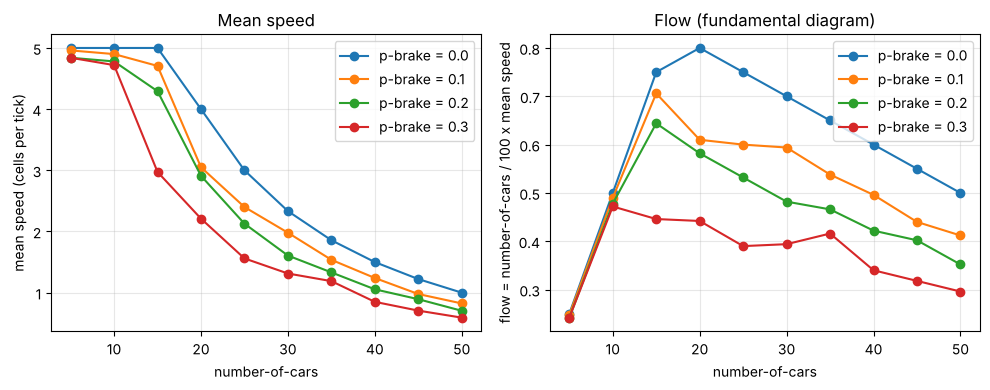

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for p, g in cells.groupby("p-brake"):
    ax[0].plot(g["number-of-cars"], g["mean"], marker="o", label=f"p-brake = {p}")
    ax[1].plot(g["number-of-cars"], g["flow"], marker="o", label=f"p-brake = {p}")
ax[0].set(xlabel="number-of-cars", ylabel="mean speed (cells per tick)", title="Mean speed")
ax[1].set(xlabel="number-of-cars", ylabel="flow = number-of-cars / 100 x mean speed", title="Flow (fundamental diagram)")
for a in ax:
    a.grid(alpha=.3)
    a.legend()
fig.tight_layout()
fig.savefig("img/fundamental-diagram.png", dpi=110)
plt.show()

In [4]:
# where is the flow highest, for each p-brake?
cells.loc[cells.groupby("p-brake")["flow"].idxmax(), ["p-brake", "number-of-cars", "flow"]].round(2)

,p-brake,number-of-cars,flow
3,0.0,20,0.80
12,0.1,15,0.71
22,0.2,15,0.64
31,0.3,10,0.47
